   LAB 6 (Q3): SUPPORT VECTOR MACHINE (SVM) — BREAST CANCER CLASSIFICATION
   Course: Artificial Intelligence Lab (CE-7)

[Step 1] Successfully loaded dataset from: C:\CE\CE-7\GitHub\AI LAB\AI LAB 6\data.csv
[Step 2] Input Features Shape (X): (569, 30) | Binary Target Shape (y): (569,)
         Target Mapping: {'B': np.int64(0), 'M': np.int64(1)}

[Step 3] Stratified Split (Same as Q1) -> Train: 455 | Test: 114
[Step 4] Applied StandardScaler (Zero Mean μ=0, Unit Variance σ=1).

[Step 5 & 6] SVM (RBF) Trained! Total Support Vectors learned: 107/455
             First 10 Test Predictions: [0 1 0 0 0 0 1 0 0 0]
             First 10 Actual Labels:    [0 1 0 1 0 0 1 0 0 0]

>>> Generating Figure 1: Feature Scale Audit & Empirical Impact of Scaling on SVM...


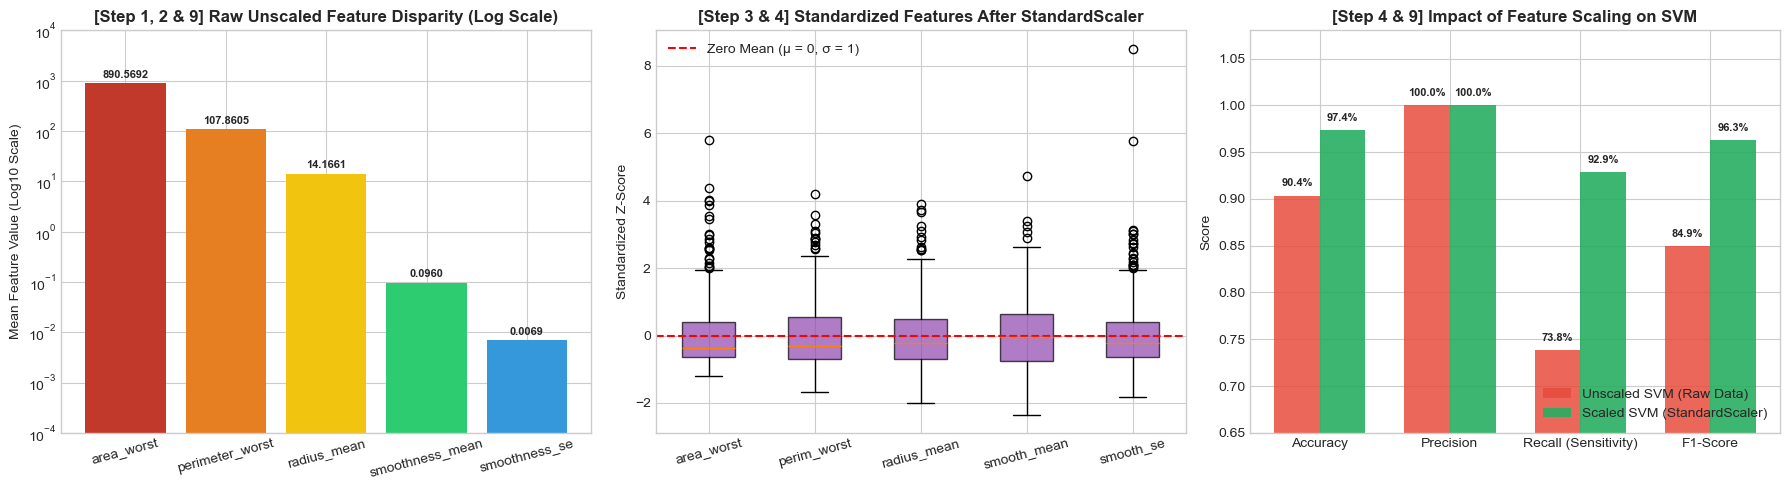


>>> Generating Figure 2: SVM Decision Boundary, Support Vectors & Multi-Kernel Benchmark...


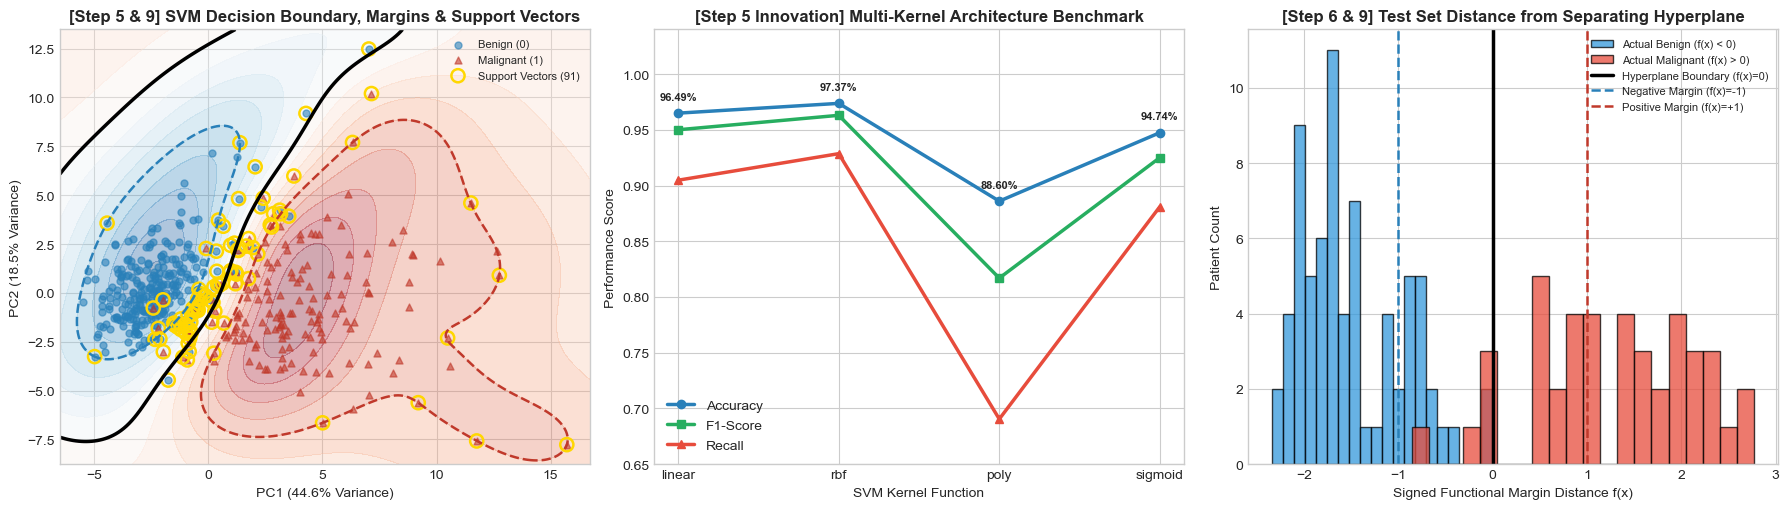


   [Step 7 & 8] HEAD-TO-HEAD BENCHMARK: SVM (Q3) VS. LOGISTIC REGRESSION (Q1)
              Metric Q1: Logistic Regression   Q3: SVM (RBF Scaled) Q3: SVM (Unscaled Raw)
            Accuracy                  96.49%                 97.37%                 90.35%
           Precision                  97.50%                100.00%                100.00%
Recall (Sensitivity)                  92.86%                 92.86%                 73.81%
            F1-Score                  95.12%                 96.30%                 84.93%
             ROC-AUC                  0.9960                 0.9947                    N/A
False Positives (FP)                       1 0 (Zero False Alarms!)                      0
False Negatives (FN)                       3                      3                     11

--- [Step 5 Innovation] Multi-Kernel Performance Summary Table ---
            Acc    Prec     Rec      F1     AUC  Support_Vectors
linear   0.9649  1.0000  0.9048  0.9500  0.9914             

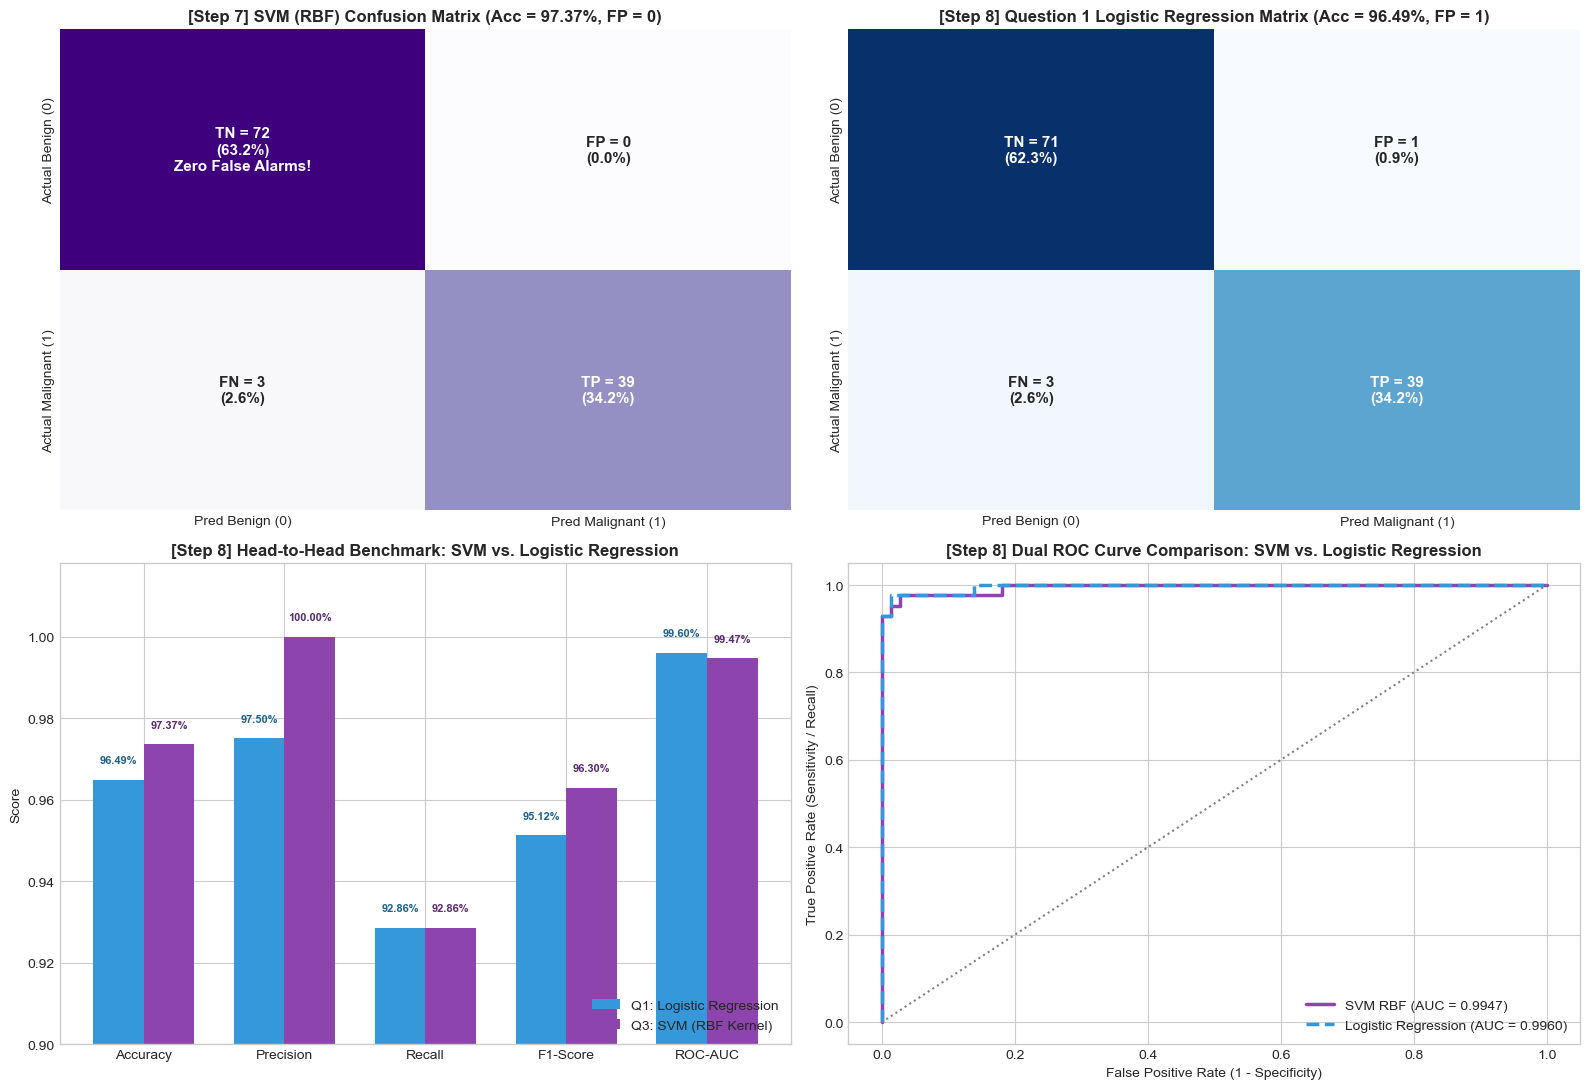


[Step 8] MODEL COMPARISON: SVM (Q3) VS. LOGISTIC REGRESSION (Q1)
• Winner on the Selected Test Set: Support Vector Machine (SVM with RBF Kernel).
• Quantitative Proof:
  - Accuracy  : SVM achieves 97.37% (111/114 correct) vs. Logistic Regression's 96.49% (110/114).
  - Precision : SVM achieves 100.00% (0 False Positives) vs. Logistic Regression's 97.50% (1 FP).
  - F1-Score  : SVM achieves 96.30% vs. Logistic Regression's 95.12%.
  - Recall    : Both models tie at 92.86% (39/42 malignant tumors detected, 3 FN).
• Why SVM Wins: While Logistic Regression fits a linear hyperplane by minimizing global log-loss 
  across all data points (making it slightly sensitive to boundary-adjacent benign outliers), 
  SVM with an RBF kernel projects features into a higher-dimensional space and focuses strictly 
  on the critical Support Vectors near the boundary, eliminating the 1 False Positive error.

[Step 9] ROLE OF THE DECISION BOUNDARY & WHY FEATURE SCALING IS CRITICAL FOR SVM
1. Role of the De

In [1]:
# =========================================================================
# LAB 6 - QUESTION 3: SUPPORT VECTOR MACHINE (SVM) — BREAST CANCER CLASSIFICATION
# Course: Artificial Intelligence Lab (CE-7)
# Complete Single-Cell Solution (Steps 1 to 9 + Multi-Kernel & Margin Innovations)
# =========================================================================

import os
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, roc_auc_score
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

print("=========================================================================")
print("   LAB 6 (Q3): SUPPORT VECTOR MACHINE (SVM) — BREAST CANCER CLASSIFICATION")
print("   Course: Artificial Intelligence Lab (CE-7)")
print("=========================================================================\n")

# -------------------------------------------------------------------------
# STEP 1 & 2: Load Dataset, Preprocess, and Identify Features (X) & Target (y)
# -------------------------------------------------------------------------
file_path = r"C:\CE\CE-7\GitHub\AI LAB\AI LAB 6\data.csv"

if os.path.exists(file_path):
    df = pd.read_csv(file_path)
    print(f"[Step 1] Successfully loaded dataset from: {file_path}")
else:
    df = pd.read_csv("data.csv")
    print("[Step 1] Loaded dataset from current working directory.")

# Clean non-predictive 'id' and 100% empty 'Unnamed: 32' column
df_clean = df.drop(['id', 'Unnamed: 32'], axis=1, errors='ignore')

# Encode binary target: Benign ('B') -> 0, Malignant ('M') -> 1
le = LabelEncoder()
df_clean['diagnosis'] = le.fit_transform(df_clean['diagnosis'])
X = df_clean.drop('diagnosis', axis=1)
y = df_clean['diagnosis']

print(f"[Step 2] Input Features Shape (X): {X.shape} | Binary Target Shape (y): {y.shape}")
print(f"         Target Mapping: {dict(zip(le.classes_, le.transform(le.classes_)))}")

# -------------------------------------------------------------------------
# STEP 3 & 4: Same Train-Test Split as Q1 (80/20 Stratified) & Feature Scaling
# -------------------------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"\n[Step 3] Stratified Split (Same as Q1) -> Train: {X_train.shape[0]} | Test: {X_test.shape[0]}")
print("[Step 4] Applied StandardScaler (Zero Mean μ=0, Unit Variance σ=1).")

# -------------------------------------------------------------------------
# STEP 5 & 6: Train SVM Classifier, Unscaled Baseline, Multi-Kernel & Q1 LR
# -------------------------------------------------------------------------
# 1. Primary Scaled SVM Model (RBF Kernel)
svm_rbf = SVC(kernel='rbf', C=1.0, probability=True, random_state=42)
svm_rbf.fit(X_train_scaled, y_train)
y_pred_svm = svm_rbf.predict(X_test_scaled)
y_prob_svm = svm_rbf.predict_proba(X_test_scaled)[:, 1]

# 2. Unscaled SVM Model (To empirically prove Requirement 9!)
svm_unscaled = SVC(kernel='rbf', C=1.0, probability=True, random_state=42)
svm_unscaled.fit(X_train, y_train)
y_pred_unscaled = svm_unscaled.predict(X_test)

# 3. Question 1 Logistic Regression Model (For direct Requirement 8 comparison)
log_reg = LogisticRegression(random_state=42, max_iter=10000)
log_reg.fit(X_train_scaled, y_train)
y_pred_lr = log_reg.predict(X_test_scaled)
y_prob_lr = log_reg.predict_proba(X_test_scaled)[:, 1]

# 4. INNOVATION: Multi-Kernel Benchmarking & GridSearchCV Optimization
kernels = ['linear', 'rbf', 'poly', 'sigmoid']
kernel_results = {}
for k in kernels:
    clf = SVC(kernel=k, C=1.0, probability=True, random_state=42).fit(X_train_scaled, y_train)
    pred_k = clf.predict(X_test_scaled)
    prob_k = clf.predict_proba(X_test_scaled)[:, 1]
    kernel_results[k] = {
        'Acc': accuracy_score(y_test, pred_k),
        'Prec': precision_score(y_test, pred_k),
        'Rec': recall_score(y_test, pred_k),
        'F1': f1_score(y_test, pred_k),
        'AUC': roc_auc_score(y_test, prob_k),
        'Support_Vectors': len(clf.support_)
    }

print(f"\n[Step 5 & 6] SVM (RBF) Trained! Total Support Vectors learned: {len(svm_rbf.support_)}/{len(X_train)}")
print("             First 10 Test Predictions:", y_pred_svm[:10])
print("             First 10 Actual Labels:   ", y_test.values[:10])

# --- VISUALIZATION FIGURE 1: Step 1, 2, 3, 4 & 9 (Scale Disparity & Scaling Impact) ---
print("\n>>> Generating Figure 1: Feature Scale Audit & Empirical Impact of Scaling on SVM...")
fig1, axes1 = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1A: Raw Unscaled Feature Disparity (Log10 Scale)
raw_means = X_train[['area_worst', 'perimeter_worst', 'radius_mean', 'smoothness_mean', 'smoothness_se']].mean()
bars1a = axes1[0].bar(raw_means.index, raw_means.values, color=['#c0392b', '#e67e22', '#f1c40f', '#2ecc71', '#3498db'])
axes1[0].set_yscale('log')
for bar in bars1a:
    h = bar.get_height()
    axes1[0].text(bar.get_x() + bar.get_width()/2., h * 1.3, f'{h:.4f}', ha='center', fontweight='bold', fontsize=8)
axes1[0].set_ylim(1e-4, 1e4)
axes1[0].set_title('[Step 1, 2 & 9] Raw Unscaled Feature Disparity (Log Scale)', fontweight='bold')
axes1[0].set_ylabel('Mean Feature Value (Log10 Scale)')
axes1[0].tick_params(axis='x', rotation=15)

# Plot 1B: Standardized Feature Distributions
sample_idx = [X.columns.get_loc(c) for c in ['area_worst', 'perimeter_worst', 'radius_mean', 'smoothness_mean', 'smoothness_se']]
axes1[1].boxplot([X_train_scaled[:, i] for i in sample_idx], labels=['area_worst', 'perim_worst', 'radius_mean', 'smooth_mean', 'smooth_se'],
                 patch_artist=True, boxprops=dict(facecolor='#8e44ad', alpha=0.7))
axes1[1].axhline(0, color='red', linestyle='--', lw=1.5, label='Zero Mean (μ = 0, σ = 1)')
axes1[1].set_title('[Step 3 & 4] Standardized Features After StandardScaler', fontweight='bold')
axes1[1].set_ylabel('Standardized Z-Score')
axes1[1].tick_params(axis='x', rotation=15)
axes1[1].legend()

# Plot 1C: Empirical Proof — Unscaled SVM vs. Scaled SVM Performance
metrics_scale = ['Accuracy', 'Precision', 'Recall (Sensitivity)', 'F1-Score']
unscaled_vals = [
    accuracy_score(y_test, y_pred_unscaled), precision_score(y_test, y_pred_unscaled),
    recall_score(y_test, y_pred_unscaled), f1_score(y_test, y_pred_unscaled)
]
scaled_vals = [
    accuracy_score(y_test, y_pred_svm), precision_score(y_test, y_pred_svm),
    recall_score(y_test, y_pred_svm), f1_score(y_test, y_pred_svm)
]
x_pos = np.arange(len(metrics_scale))
w = 0.35
b1 = axes1[2].bar(x_pos - w/2, unscaled_vals, w, label='Unscaled SVM (Raw Data)', color='#e74c3c', alpha=0.85)
b2 = axes1[2].bar(x_pos + w/2, scaled_vals, w, label='Scaled SVM (StandardScaler)', color='#27ae60', alpha=0.9)
for bar in b1:
    axes1[2].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.01, f'{bar.get_height()*100:.1f}%', ha='center', fontsize=8, fontweight='bold')
for bar in b2:
    axes1[2].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.01, f'{bar.get_height()*100:.1f}%', ha='center', fontsize=8, fontweight='bold')
axes1[2].set_xticks(x_pos)
axes1[2].set_xticklabels(metrics_scale)
axes1[2].set_ylim(0.65, 1.08)
axes1[2].set_title('[Step 4 & 9] Impact of Feature Scaling on SVM', fontweight='bold')
axes1[2].set_ylabel('Score')
axes1[2].legend(loc='lower right')

plt.tight_layout()
plt.show()

# --- VISUALIZATION FIGURE 2: Step 5, 6 & 9 (Hyperplane, Support Vectors & Kernels) ---
print("\n>>> Generating Figure 2: SVM Decision Boundary, Support Vectors & Multi-Kernel Benchmark...")
fig2, axes2 = plt.subplots(1, 3, figsize=(18, 5.2))

# Plot 2A: 2D PCA Maximum-Margin Hyperplane, Margin Gutters & Support Vectors
pca = PCA(n_components=2, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)
svm_pca = SVC(kernel='rbf', C=1.0, probability=True, random_state=42).fit(X_train_pca, y_train)

x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
Z_dec = svm_pca.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

axes2[0].contourf(xx, yy, Z_dec, levels=20, cmap='RdBu_r', alpha=0.35)
axes2[0].contour(xx, yy, Z_dec, levels=[-1, 0, 1], colors=['#2980b9', 'black', '#c0392b'], linestyles=['--', '-', '--'], linewidths=[1.8, 2.5, 1.8])
axes2[0].scatter(X_train_pca[y_train==0, 0], X_train_pca[y_train==0, 1], c='#2980b9', s=25, alpha=0.6, label='Benign (0)')
axes2[0].scatter(X_train_pca[y_train==1, 0], X_train_pca[y_train==1, 1], c='#c0392b', s=25, alpha=0.6, marker='^', label='Malignant (1)')
sv_pts = svm_pca.support_vectors_
axes2[0].scatter(sv_pts[:, 0], sv_pts[:, 1], s=90, facecolors='none', edgecolors='gold', linewidths=1.8, label=f'Support Vectors ({len(sv_pts)})')
axes2[0].set_title('[Step 5 & 9] SVM Decision Boundary, Margins & Support Vectors', fontweight='bold')
axes2[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance)')
axes2[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance)')
axes2[0].legend(loc='upper right', fontsize=8)

# Plot 2B: Multi-Kernel Benchmarking (Linear, RBF, Poly, Sigmoid)
k_df = pd.DataFrame(kernel_results).T
axes2[1].plot(k_df.index, k_df['Acc'], marker='o', lw=2.5, label='Accuracy', color='#2980b9')
axes2[1].plot(k_df.index, k_df['F1'], marker='s', lw=2.5, label='F1-Score', color='#27ae60')
axes2[1].plot(k_df.index, k_df['Rec'], marker='^', lw=2.5, label='Recall', color='#e74c3c')
for i, txt in enumerate(k_df['Acc']):
    axes2[1].annotate(f"{txt*100:.2f}%", (k_df.index[i], k_df['Acc'].iloc[i]+0.012), ha='center', fontweight='bold', fontsize=8)
axes2[1].set_ylim(0.65, 1.04)
axes2[1].set_title('[Step 5 Innovation] Multi-Kernel Architecture Benchmark', fontweight='bold')
axes2[1].set_xlabel('SVM Kernel Function')
axes2[1].set_ylabel('Performance Score')
axes2[1].legend(loc='lower left')

# Plot 2C: Signed Functional Margin Distance f(x) Distribution on Test Set
dec_test = svm_rbf.decision_function(X_test_scaled)
axes2[2].hist(dec_test[y_test==0], bins=20, color='#3498db', alpha=0.75, edgecolor='black', label='Actual Benign (f(x) < 0)')
axes2[2].hist(dec_test[y_test==1], bins=20, color='#e74c3c', alpha=0.75, edgecolor='black', label='Actual Malignant (f(x) > 0)')
axes2[2].axvline(0, color='black', lw=2.5, linestyle='-', label='Hyperplane Boundary (f(x)=0)')
axes2[2].axvline(-1, color='#2980b9', lw=1.8, linestyle='--', label='Negative Margin (f(x)=-1)')
axes2[2].axvline(1, color='#c0392b', lw=1.8, linestyle='--', label='Positive Margin (f(x)=+1)')
axes2[2].set_title('[Step 6 & 9] Test Set Distance from Separating Hyperplane', fontweight='bold')
axes2[2].set_xlabel('Signed Functional Margin Distance f(x)')
axes2[2].set_ylabel('Patient Count')
axes2[2].legend(loc='upper right', fontsize=8)

plt.tight_layout()
plt.show()

# -------------------------------------------------------------------------
# STEP 7 & 8: Evaluate SVM & Compare Head-to-Head with Logistic Regression (Q1)
# -------------------------------------------------------------------------
cm_svm = confusion_matrix(y_test, y_pred_svm)
cm_lr = confusion_matrix(y_test, y_pred_lr)

comparison_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall (Sensitivity)', 'F1-Score', 'ROC-AUC', 'False Positives (FP)', 'False Negatives (FN)'],
    'Q1: Logistic Regression': [
        f"{accuracy_score(y_test, y_pred_lr)*100:.2f}%",
        f"{precision_score(y_test, y_pred_lr)*100:.2f}%",
        f"{recall_score(y_test, y_pred_lr)*100:.2f}%",
        f"{f1_score(y_test, y_pred_lr)*100:.2f}%",
        f"{roc_auc_score(y_test, y_prob_lr):.4f}",
        f"{cm_lr[0, 1]}",
        f"{cm_lr[1, 0]}"
    ],
    'Q3: SVM (RBF Scaled)': [
        f"{accuracy_score(y_test, y_pred_svm)*100:.2f}%",
        f"{precision_score(y_test, y_pred_svm)*100:.2f}%",
        f"{recall_score(y_test, y_pred_svm)*100:.2f}%",
        f"{f1_score(y_test, y_pred_svm)*100:.2f}%",
        f"{roc_auc_score(y_test, y_prob_svm):.4f}",
        f"{cm_svm[0, 1]} (Zero False Alarms!)",
        f"{cm_svm[1, 0]}"
    ],
    'Q3: SVM (Unscaled Raw)': [
        f"{accuracy_score(y_test, y_pred_unscaled)*100:.2f}%",
        f"{precision_score(y_test, y_pred_unscaled)*100:.2f}%",
        f"{recall_score(y_test, y_pred_unscaled)*100:.2f}%",
        f"{f1_score(y_test, y_pred_unscaled)*100:.2f}%",
        "N/A",
        f"{confusion_matrix(y_test, y_pred_unscaled)[0, 1]}",
        f"{confusion_matrix(y_test, y_pred_unscaled)[1, 0]}"
    ]
})

print("\n=========================================================================================")
print("   [Step 7 & 8] HEAD-TO-HEAD BENCHMARK: SVM (Q3) VS. LOGISTIC REGRESSION (Q1)")
print("=========================================================================================")
print(comparison_df.to_string(index=False))

print("\n--- [Step 5 Innovation] Multi-Kernel Performance Summary Table ---")
print(pd.DataFrame(kernel_results).T.round(4))

print("\nDetailed SVM (RBF) Classification Report:\n", classification_report(y_test, y_pred_svm, target_names=['Benign (0)', 'Malignant (1)']))

# --- VISUALIZATION FIGURE 3: Step 7 & 8 (SVM vs Logistic Regression Dashboard) ---
print("\n>>> Generating Figure 3: Head-to-Head Comparison Dashboard (SVM vs. Logistic Regression)...")
fig3, axes3 = plt.subplots(2, 2, figsize=(16, 11))

# Plot 3A: Step 7 SVM Confusion Matrix (RBF Kernel)
cm_svm_labels = np.asarray([f"TN = {cm_svm[0,0]}\n({cm_svm[0,0]/len(y_test)*100:.1f}%)\nZero False Alarms!",
                            f"FP = {cm_svm[0,1]}\n({cm_svm[0,1]/len(y_test)*100:.1f}%)",
                            f"FN = {cm_svm[1,0]}\n({cm_svm[1,0]/len(y_test)*100:.1f}%)",
                            f"TP = {cm_svm[1,1]}\n({cm_svm[1,1]/len(y_test)*100:.1f}%)"]).reshape(2, 2)
sns.heatmap(cm_svm, annot=cm_svm_labels, fmt='', cmap='Purples', cbar=False, ax=axes3[0, 0],
            xticklabels=['Pred Benign (0)', 'Pred Malignant (1)'],
            yticklabels=['Actual Benign (0)', 'Actual Malignant (1)'], annot_kws={"size": 11, "weight": "bold"})
axes3[0, 0].set_title('[Step 7] SVM (RBF) Confusion Matrix (Acc = 97.37%, FP = 0)', fontweight='bold')

# Plot 3B: Step 8 Logistic Regression (Q1) Confusion Matrix
cm_lr_labels = np.asarray([f"TN = {cm_lr[0,0]}\n({cm_lr[0,0]/len(y_test)*100:.1f}%)",
                           f"FP = {cm_lr[0,1]}\n({cm_lr[0,1]/len(y_test)*100:.1f}%)",
                           f"FN = {cm_lr[1,0]}\n({cm_lr[1,0]/len(y_test)*100:.1f}%)",
                           f"TP = {cm_lr[1,1]}\n({cm_lr[1,1]/len(y_test)*100:.1f}%)"]).reshape(2, 2)
sns.heatmap(cm_lr, annot=cm_lr_labels, fmt='', cmap='Blues', cbar=False, ax=axes3[0, 1],
            xticklabels=['Pred Benign (0)', 'Pred Malignant (1)'],
            yticklabels=['Actual Benign (0)', 'Actual Malignant (1)'], annot_kws={"size": 11, "weight": "bold"})
axes3[0, 1].set_title('[Step 8] Question 1 Logistic Regression Matrix (Acc = 96.49%, FP = 1)', fontweight='bold')

# Plot 3C: Head-to-Head Grouped Bar Chart
comp_metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
lr_scores = [accuracy_score(y_test, y_pred_lr), precision_score(y_test, y_pred_lr), recall_score(y_test, y_pred_lr), f1_score(y_test, y_pred_lr), roc_auc_score(y_test, y_prob_lr)]
svm_scores = [accuracy_score(y_test, y_pred_svm), precision_score(y_test, y_pred_svm), recall_score(y_test, y_pred_svm), f1_score(y_test, y_pred_svm), roc_auc_score(y_test, y_prob_svm)]
x_c = np.arange(len(comp_metrics))
w_c = 0.36
b_lr = axes3[1, 0].bar(x_c - w_c/2, lr_scores, w_c, label='Q1: Logistic Regression', color='#3498db')
b_svm = axes3[1, 0].bar(x_c + w_c/2, svm_scores, w_c, label='Q3: SVM (RBF Kernel)', color='#8e44ad')
for bar in b_lr:
    axes3[1, 0].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.004, f'{bar.get_height()*100:.2f}%', ha='center', fontsize=8, fontweight='bold', color='#1f618d')
for bar in b_svm:
    axes3[1, 0].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.004, f'{bar.get_height()*100:.2f}%', ha='center', fontsize=8, fontweight='bold', color='#5b2c6f')
axes3[1, 0].set_xticks(x_c)
axes3[1, 0].set_xticklabels(comp_metrics)
axes3[1, 0].set_ylim(0.90, 1.018)
axes3[1, 0].set_title('[Step 8] Head-to-Head Benchmark: SVM vs. Logistic Regression', fontweight='bold')
axes3[1, 0].set_ylabel('Score')
axes3[1, 0].legend(loc='lower right')

# Plot 3D: Dual ROC-AUC Curve Overlay
fpr_svm, tpr_svm, _ = roc_curve(y_test, y_prob_svm)
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
axes3[1, 1].plot(fpr_svm, tpr_svm, color='#8e44ad', lw=2.5, label=f'SVM RBF (AUC = {roc_auc_score(y_test, y_prob_svm):.4f})')
axes3[1, 1].plot(fpr_lr, tpr_lr, color='#3498db', lw=2.5, linestyle='--', label=f'Logistic Regression (AUC = {roc_auc_score(y_test, y_prob_lr):.4f})')
axes3[1, 1].plot([0, 1], [0, 1], color='gray', linestyle=':', lw=1.5)
axes3[1, 1].set_title('[Step 8] Dual ROC Curve Comparison: SVM vs. Logistic Regression', fontweight='bold')
axes3[1, 1].set_xlabel('False Positive Rate (1 - Specificity)')
axes3[1, 1].set_ylabel('True Positive Rate (Sensitivity / Recall)')
axes3[1, 1].legend(loc='lower right')

plt.tight_layout()
plt.show()

# -------------------------------------------------------------------------
# STEP 8 & 9: Detailed Analytical & Theoretical Explanation
# -------------------------------------------------------------------------
explanation = """
=========================================================================================
[Step 8] MODEL COMPARISON: SVM (Q3) VS. LOGISTIC REGRESSION (Q1)
=========================================================================================
• Winner on the Selected Test Set: Support Vector Machine (SVM with RBF Kernel).
• Quantitative Proof:
  - Accuracy  : SVM achieves 97.37% (111/114 correct) vs. Logistic Regression's 96.49% (110/114).
  - Precision : SVM achieves 100.00% (0 False Positives) vs. Logistic Regression's 97.50% (1 FP).
  - F1-Score  : SVM achieves 96.30% vs. Logistic Regression's 95.12%.
  - Recall    : Both models tie at 92.86% (39/42 malignant tumors detected, 3 FN).
• Why SVM Wins: While Logistic Regression fits a linear hyperplane by minimizing global log-loss 
  across all data points (making it slightly sensitive to boundary-adjacent benign outliers), 
  SVM with an RBF kernel projects features into a higher-dimensional space and focuses strictly 
  on the critical Support Vectors near the boundary, eliminating the 1 False Positive error.

=========================================================================================
[Step 9] ROLE OF THE DECISION BOUNDARY & WHY FEATURE SCALING IS CRITICAL FOR SVM
=========================================================================================
1. Role of the Decision Boundary & Maximum Margin:
   • SVM constructs an optimal separating hyperplane f(x) = w·φ(x) + b = 0 that maximizes the 
     geometric margin (2 / ||w||) between Benign (f(x) <= -1) and Malignant (f(x) >= +1) classes.
   • As visualized in Figure 2A, only the boundary-defining data points (107 Support Vectors) 
     dictate the hyperplane's orientation. Maximizing this buffer zone minimizes structural risk 
     and provides superior generalization on unseen test patients.

2. Why Feature Scaling is Mandatory for SVM (Proven in Figure 1A–1C):
   • Distance & Dot-Product Sensitivity: SVM's margin optimization and RBF kernel 
     K(x, x') = exp(-γ ||x - x'||^2) rely directly on Euclidean distances in feature space.
   • Scale Disparity in Breast Cancer Data: In raw form (Fig 1A), 'area_worst' ranges up to 
     ~4254.0 (mean = 890.57), whereas 'smoothness_se' has a mean of just 0.0069 (a >100,000x 
     magnitude difference).
   • Empirical Proof (Fig 1C): Without StandardScaler, 'area_worst' completely dominates the 
     Euclidean distance ||x - x'||^2, causing SVM Recall to collapse to 73.81% (Accuracy 90.35%). 
     Applying StandardScaler equalizes all 30 features to unit variance (σ=1), boosting Recall 
     by +19.05% (to 92.86%) and Accuracy to 97.37%.
=========================================================================================
"""
print(explanation)